# 04. Исследовательский анализ (EDA)

**Вход:** `data/clean_flats.pkl` — 5580 объявлений (продажа и аренда, Астана).

Вопросы для агентства:
1. Как распределены цены и что считать «типичной» квартирой?
2. Чем отличаются районы и берега по цене продажи и аренды?
3. Как число комнат, этаж и высотность дома влияют на цену за м²?
4. Какие признаки связаны между собой (корреляции)?
5. Что получает клиент с бюджетом 20–50 млн ₸ в разных районах?

> Цифры в выводах посчитаны на выгрузке 3 ноября 2026 года. При новой выгрузке они немного изменятся.

In [2]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

BANK_COLORS = {"Левый берег": "#4C72B0", "Правый берег": "#DD8452"}
DISTRICT_ORDER = ["Есильский", "Нура", "Сарайшык", "Алматинский", "Сарыарка", "Байконур"]

df = pd.read_pickle("data/clean_flats.pkl")
sale = df[df["deal"] == "sale"]
rent = df[df["deal"] == "rent"]
# убираем «Не указан» и неиспользуемые категории, чтобы они не попадали в графики
sale_d = sale[sale["has_district"]].assign(district=lambda x: x["district"].astype(str),
                                           bank=lambda x: x["bank"].astype(str))
rent_d = rent[rent["has_district"]].assign(district=lambda x: x["district"].astype(str),
                                           bank=lambda x: x["bank"].astype(str))

thousands = mtick.FuncFormatter(lambda x, _: f"{x / 1000:,.0f}".replace(",", " "))
print(f"Продажа: {len(sale)} | аренда: {len(rent)}")

Продажа: 2922 | аренда: 2658


## 1. Распределение цен

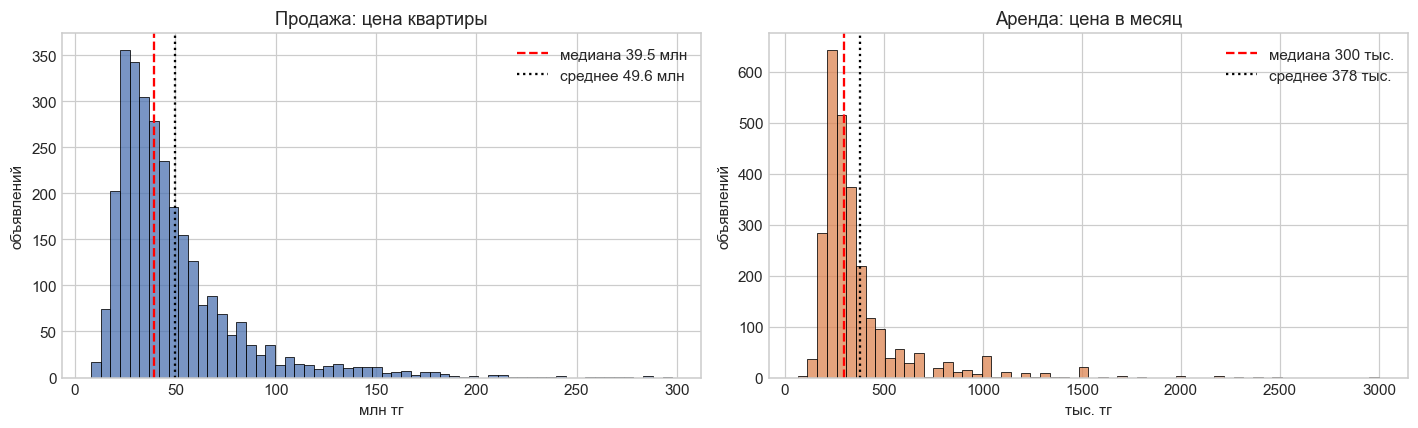

Асимметрия: продажа 2.61, аренда 3.53


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(sale["price_mln"], bins=60, ax=axes[0], color="#4C72B0")
axes[0].axvline(sale["price_mln"].median(), color="red", ls="--", label=f"медиана {sale['price_mln'].median():.1f} млн")
axes[0].axvline(sale["price_mln"].mean(), color="black", ls=":", label=f"среднее {sale['price_mln'].mean():.1f} млн")
axes[0].set(title="Продажа: цена квартиры", xlabel="млн тг", ylabel="объявлений"); axes[0].legend()

sns.histplot(rent["price_kzt"] / 1000, bins=60, ax=axes[1], color="#DD8452")
axes[1].axvline(rent["price_kzt"].median() / 1000, color="red", ls="--", label=f"медиана {rent['price_kzt'].median() / 1000:.0f} тыс.")
axes[1].axvline(rent["price_kzt"].mean() / 1000, color="black", ls=":", label=f"среднее {rent['price_kzt'].mean() / 1000:.0f} тыс.")
axes[1].set(title="Аренда: цена в месяц", xlabel="тыс. тг", ylabel="объявлений"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"Асимметрия: продажа {sale['price_kzt'].skew():.2f}, аренда {rent['price_kzt'].skew():.2f}")

**Вывод.** Оба распределения сильно скошены вправо: среднее (≈49,6 млн ₸ и ≈378 тыс. ₸) заметно выше
медианы (39,5 млн ₸ и 300 тыс. ₸) из-за дорогих квартир. Поэтому дальше везде используем **медианы**,
а в статистических тестах — непараметрический U-критерий Манна–Уитни.
**Типичная сделка:** квартира за ≈40 млн ₸, которую можно сдать за ≈300 тыс. ₸ в месяц.

## 2. Районы и берега: цена продажи и аренды за м²

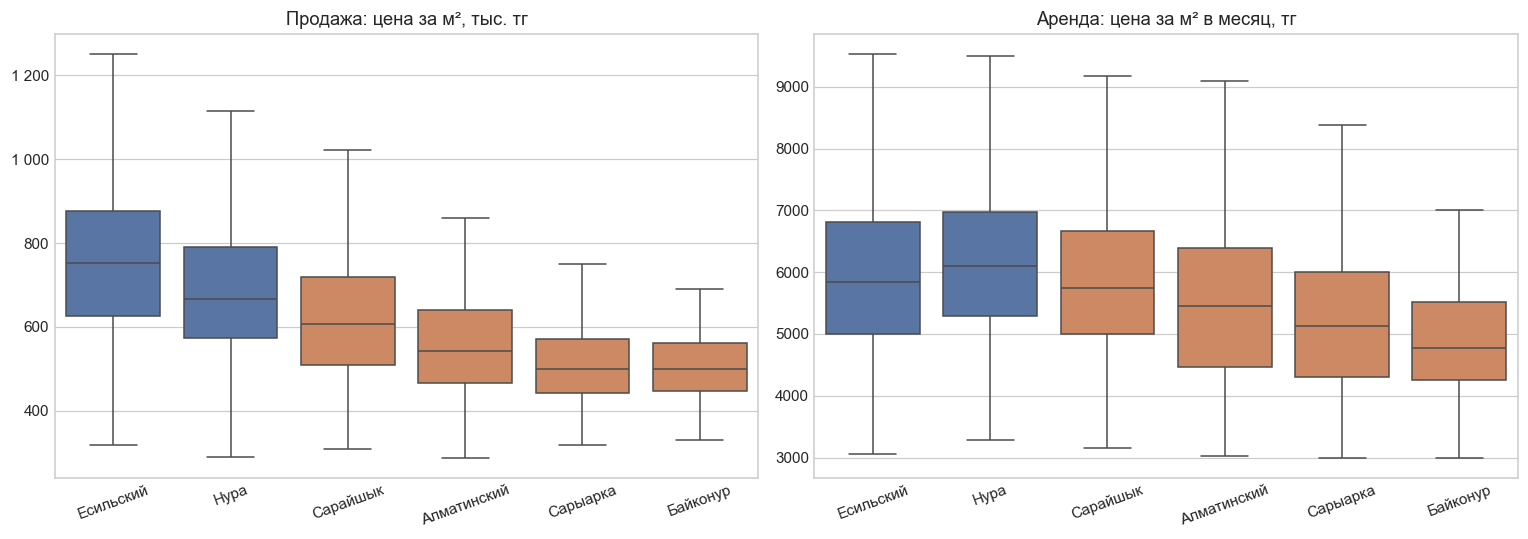

,"продажа, тг/м²","аренда, тг/м² в мес.","аренда × 12 / цена, %"
district,,,
Есильский,752000.0,5833.0,9.31
Нура,665725.5,6098.0,10.99
Сарайшык,607143.0,5750.0,11.36
Алматинский,543583.5,5452.0,12.04
Сарыарка,500000.0,5128.0,12.31
Байконур,500000.0,4776.0,11.46


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, title in [(axes[0], sale_d, "Продажа: цена за м², тыс. тг"),
                        (axes[1], rent_d, "Аренда: цена за м² в месяц, тг")]:
    palette = {d: BANK_COLORS[data.loc[data["district"] == d, "bank"].iloc[0]] for d in DISTRICT_ORDER}
    sns.boxplot(data=data, x="district", y="price_per_m2", order=DISTRICT_ORDER,
                hue="district", palette=palette, legend=False, showfliers=False, ax=ax)
    ax.set(title=title, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=20)
axes[0].yaxis.set_major_formatter(thousands)
plt.tight_layout(); plt.show()

by_district = pd.DataFrame({
    "продажа, тг/м²": sale_d.groupby("district", observed=True)["price_per_m2"].median(),
    "аренда, тг/м² в мес.": rent_d.groupby("district", observed=True)["price_per_m2"].median(),
}).loc[DISTRICT_ORDER]
by_district["аренда × 12 / цена, %"] = (by_district.iloc[:, 1] * 12 / by_district.iloc[:, 0] * 100).round(2)
by_district

**Вывод.** Левый берег (синий) заметно дороже: медианная цена за м² в Есильском районе (≈752 тыс. ₸)
**на 50% выше**, чем в Сарыарке и Байконуре (≈500 тыс. ₸). А вот аренда отличается гораздо меньше:
разброс между районами — около **28%** (от ≈4,8 до ≈6,1 тыс. ₸ за м² в месяц).
Получается, что на правом берегу инвестор платит за квадратный метр намного меньше, а арендатор — лишь немного меньше.
Это прямой аргумент в пользу гипотезы **H2**: доходность по медианам на правом берегу выше (последняя колонка таблицы).

## 3. Число комнат: структура предложения и цена за м²

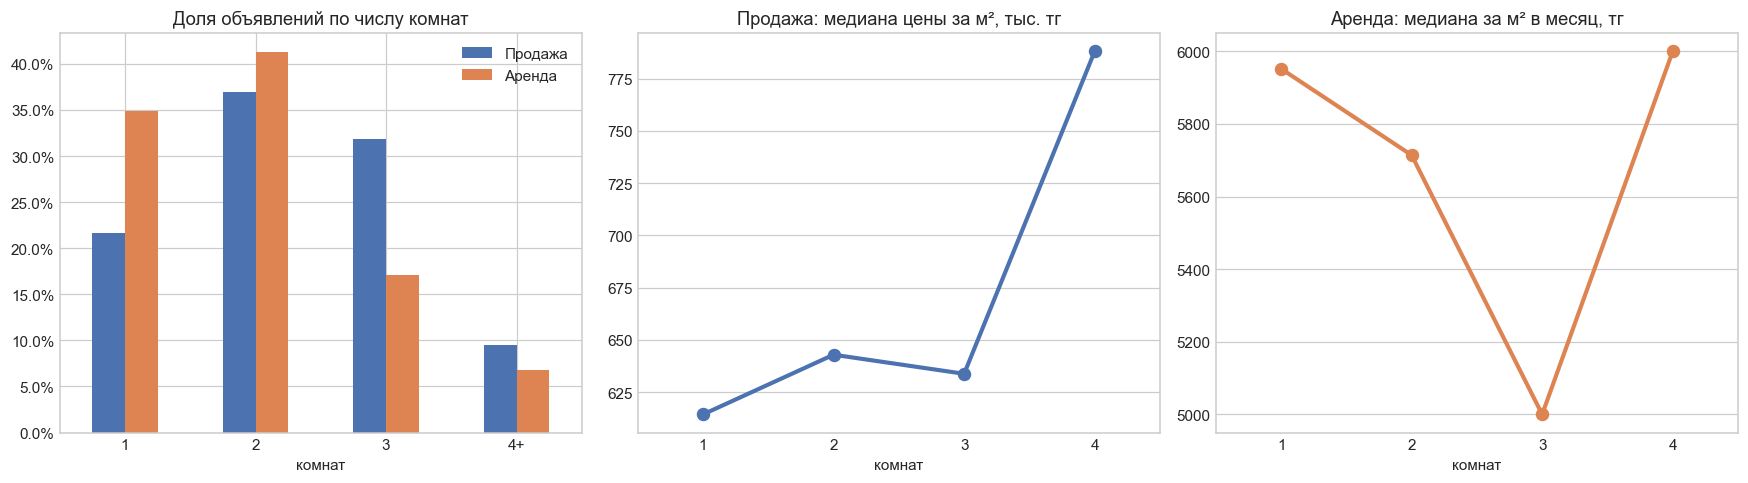

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

share = pd.DataFrame({
    "Продажа": sale["rooms_grp"].value_counts(normalize=True).sort_index(),
    "Аренда": rent["rooms_grp"].value_counts(normalize=True).sort_index(),
})
share.index = ["1", "2", "3", "4+"]
share.plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452"], rot=0)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set(title="Доля объявлений по числу комнат", xlabel="комнат", ylabel="")

sns.pointplot(data=sale, x="rooms_grp", y="price_per_m2", estimator=np.median, errorbar=None, ax=axes[1], color="#4C72B0")
axes[1].yaxis.set_major_formatter(thousands)
axes[1].set(title="Продажа: медиана цены за м², тыс. тг", xlabel="комнат", ylabel="")

sns.pointplot(data=rent, x="rooms_grp", y="price_per_m2", estimator=np.median, errorbar=None, ax=axes[2], color="#DD8452")
axes[2].set(title="Аренда: медиана за м² в месяц, тг", xlabel="комнат", ylabel="")
plt.tight_layout(); plt.show()

**Вывод.**
- **Структура рынка не совпадает:** однокомнатные — 35% объявлений аренды, но лишь 22% продажи.
  Однушки чаще сдают, чем продают, — значит, это главный формат арендного рынка.
- **Цена продажи за м² почти не зависит от числа комнат** (614–643 тыс. ₸ для 1–3 комнат),
  а **аренда за м² падает с ростом квартиры**: ≈5,95 тыс. ₸ у однушек против ≈5,0 тыс. ₸ у трёшек.
- Инвестор платит за метр однушки примерно столько же, сколько за метр трёшки, а получает за него
  на ≈19% больше аренды. Это механизм гипотезы **H1**.
- Квартиры 4+ комнат — отдельный премиальный сегмент с высокой ценой за м².

## 4. Этаж и высотность дома

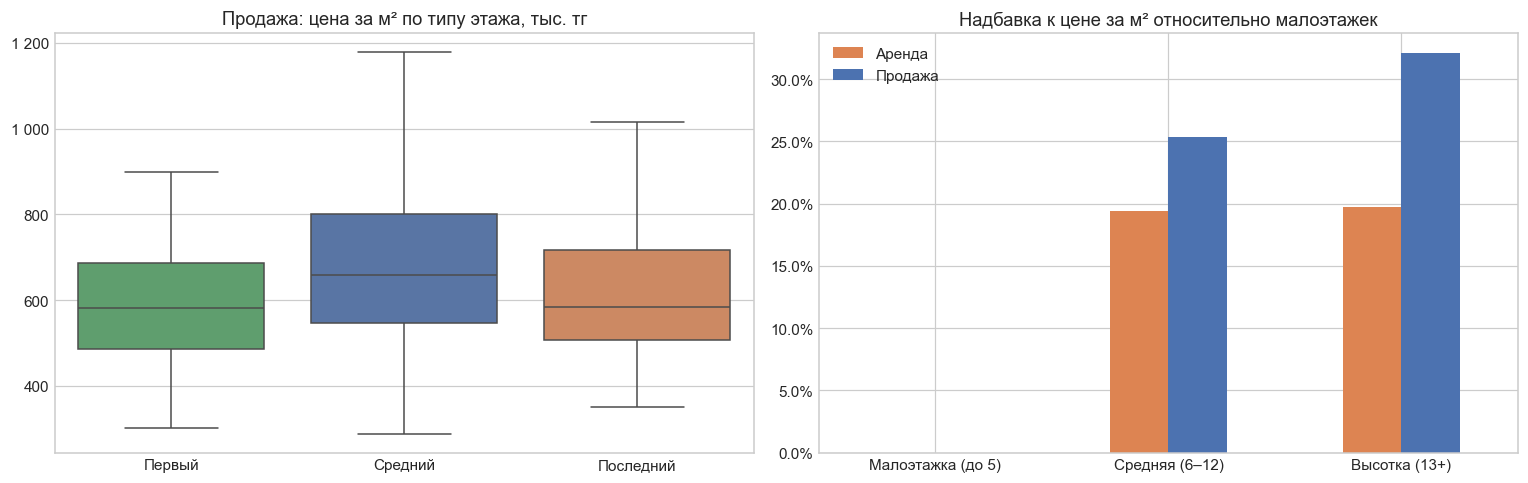

              median  count
floor_type                 
Первый      581140.0     91
Последний   583204.0    289
Средний     659625.0   2260


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
known = sale[sale["floor_type"] != "Не указан"].assign(floor_type=lambda x: x["floor_type"].astype(str))
sns.boxplot(data=known, x="floor_type", y="price_per_m2", order=["Первый", "Средний", "Последний"],
            hue="floor_type", legend=False, showfliers=False, ax=axes[0])
axes[0].yaxis.set_major_formatter(thousands)
axes[0].set(title="Продажа: цена за м² по типу этажа, тыс. тг", xlabel="", ylabel="")

h_order = ["Малоэтажка (до 5)", "Средняя (6–12)", "Высотка (13+)"]
h = df[df["building_height"].isin(h_order)].copy()
h_med = (h.groupby(["deal", "building_height"], observed=True)["price_per_m2"].median()
           .unstack(0).loc[h_order])
(h_med / h_med.iloc[0] * 100 - 100).plot.bar(ax=axes[1], rot=0, color=["#DD8452", "#4C72B0"])
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set(title="Надбавка к цене за м² относительно малоэтажек", xlabel="", ylabel="")
axes[1].legend(["Аренда", "Продажа"])
plt.tight_layout(); plt.show()

print(known.groupby("floor_type", observed=True)["price_per_m2"].agg(["median", "count"]).round(0))

**Вывод.**
- Квартиры на **первом и последнем этажах** по медиане дешевле средних примерно на **12%**
  (≈581–583 тыс. ₸ против ≈660 тыс. ₸ за м²). Это сырое сравнение без учёта района и комнат —
  честную проверку **H3** делаем на этапе 7. Квартир на первом этаже в выборке мало (91), это ограничение.
- **Высотность дома — сильный ценовой фактор:** в домах от 13 этажей метр на ≈32% дороже, чем в малоэтажках,
  а аренда — лишь на ≈20% дороже. Высотки (как правило, новостройки) дают инвестору меньшую доходность,
  но обычно их легче сдать. Высотность пойдёт в регрессию как замена году постройки, которого в данных нет.

## 5. Корреляции

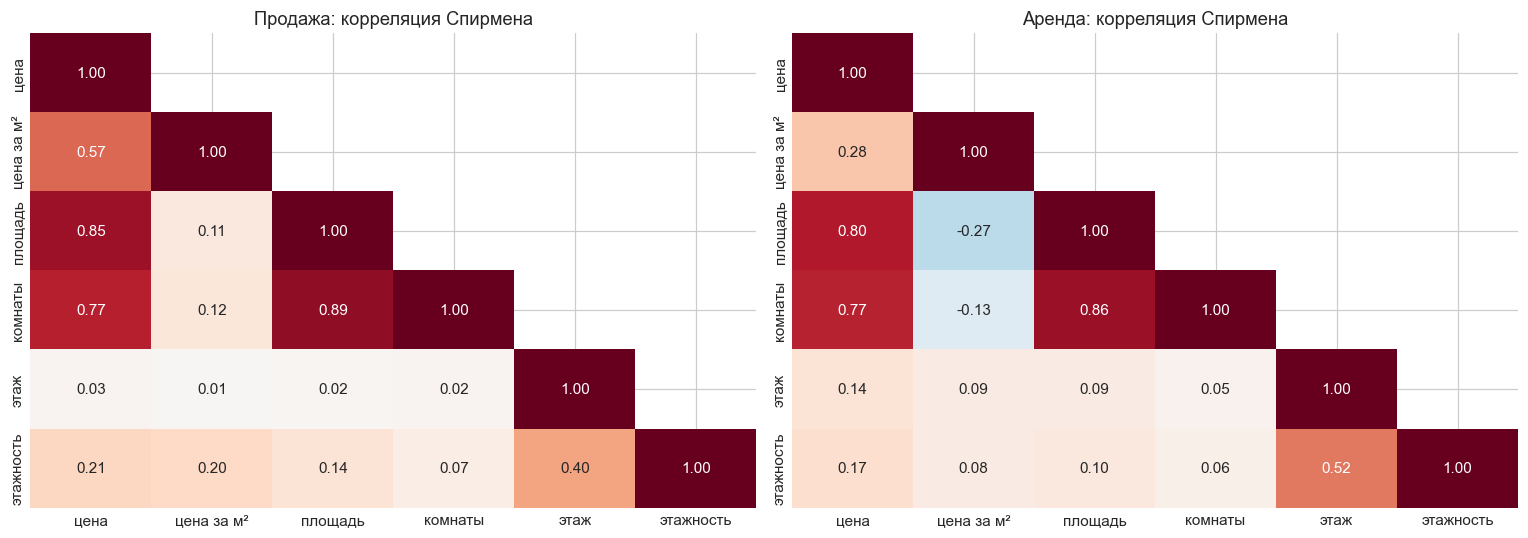

In [7]:
num_cols = {"price_kzt": "цена", "price_per_m2": "цена за м²", "area_m2": "площадь",
            "rooms": "комнаты", "floor": "этаж", "floors_total": "этажность"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, title in [(axes[0], sale, "Продажа"), (axes[1], rent, "Аренда")]:
    corr = data[list(num_cols)].astype(float).rename(columns=num_cols).corr(method="spearman")
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar=False,
                mask=np.triu(np.ones_like(corr, dtype=bool), k=1))
    ax.set_title(f"{title}: корреляция Спирмена")
plt.tight_layout(); plt.show()

**Вывод.** Используем корреляцию Спирмена — она устойчива к выбросам и нелинейности.
- Цена сильнее всего связана с **площадью** (0,85) и числом комнат (0,77). Площадь и комнаты сильно связаны
  между собой (0,89) — в регрессии оставим что-то одно или будем следить за мультиколлинеарностью.
- **Цена за м² при продаже почти не зависит от площади (0,11), а при аренде — снижается с ростом площади (−0,27).**
  Это тот же эффект, что в разделе 3: большие квартиры сдаются дешевле за метр.
- Этажность дома слабо, но положительно связана с ценой за м² (0,20) — эффект высоток.
- Сам номер этажа с ценой почти не связан (0,01–0,03): важен не этаж, а то, крайний он или нет.

## 6. Профили районов

In [8]:
profile = sale_d.groupby("district", observed=True).agg(
    объявлений=("price_kzt", "size"),
    медиана_цены_млн=("price_mln", "median"),
    медиана_площади=("area_m2", "median"),
    цена_за_м2=("price_per_m2", "median"),
    доля_высоток=("building_height", lambda x: (x == "Высотка (13+)").mean()),
    доля_однушек=("rooms", lambda x: (x == 1).mean()),
).loc[DISTRICT_ORDER]
profile["аренда/продажа"] = (rent_d.groupby("district", observed=True).size()
                             / sale_d.groupby("district", observed=True).size()).loc[DISTRICT_ORDER]
profile.style.format({"медиана_цены_млн": "{:.1f}", "медиана_площади": "{:.0f}", "цена_за_м2": "{:,.0f}",
                      "доля_высоток": "{:.0%}", "доля_однушек": "{:.0%}", "аренда/продажа": "{:.2f}"})

,объявлений,медиана_цены_млн,медиана_площади,цена_за_м2,доля_высоток,доля_однушек,аренда/продажа
district,,,,,,,
Есильский,885,50.3,72,"752,000",34%,18%,1.21
Нура,906,39.5,63,"665,726",35%,21%,0.75
Сарайшык,363,36.5,63,"607,143",23%,23%,0.52
Алматинский,372,32.5,65,"543,584",31%,22%,1.02
Сарыарка,268,26.7,51,"500,000",26%,36%,0.72
Байконур,84,33.8,68,"500,000",51%,21%,0.74


**Вывод.**
- **Есильский** — самый дорогой и самый «арендный» район: на одно объявление о продаже приходится
  **1,2 объявления об аренде**. Предложение аренды большое, значит, выше конкуренция за арендатора
  и риск простоя.
- **Нура** — самый большой рынок продажи (≈906 объявлений, 31% предложения): район массовых новых ЖК.
  Цена за м² (≈666 тыс. ₸) ниже Есильского района примерно на 11%, медианная квартира — 39,5 млн ₸ за 63 м².
  На одну продажу — 0,75 объявления аренды: конкуренция за арендатора умеренная.
  Это «вход на левый берег» для инвестора с ограниченным бюджетом.
- **Алматинский** — сбалансированный район правого берега: цена за м² (≈544 тыс. ₸) на 28% ниже Есильского,
  а медианная квартира больше (65 м² за 32,5 млн ₸). Аренды и продажи примерно поровну (1,0 : 1),
  то есть спрос и предложение уравновешены. Доходность здесь стабильно высокая почти во всех форматах
  (см. раздел метрик).
- **Сарайшык** — обратная ситуация: 0,5 объявления аренды на одно объявление продажи.
  Сдаваемых квартир мало — для собственника меньше конкуренции.
- **Сарыарка** — самый доступный район (медиана 26,7 млн ₸) и район однушек (36% предложения).
- **Байконур** — мало объявлений (84), выводы по нему менее надёжны.

## 7. Что получает клиент с бюджетом 20–50 млн ₸

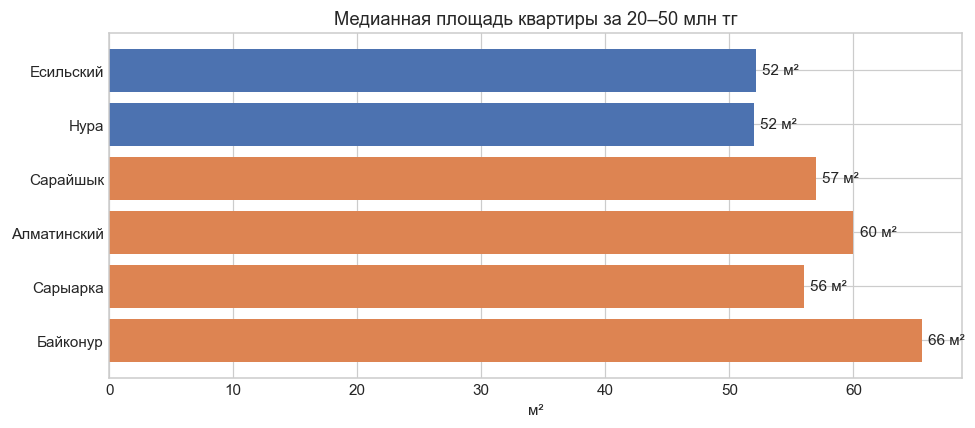

,квартир_в_бюджете,медиана_площади,доля_рынка_района
district,,,
Есильский,426,52,48%
Нура,587,52,65%
Сарайшык,247,57,68%
Алматинский,263,60,71%
Сарыарка,187,56,70%
Байконур,62,66,74%


In [9]:
budget = sale_d[sale_d["in_client_budget"]]
b = budget.groupby("district", observed=True).agg(
    квартир_в_бюджете=("area_m2", "size"),
    медиана_площади=("area_m2", "median"),
).loc[DISTRICT_ORDER]
b["доля_рынка_района"] = sale_d.groupby("district", observed=True)["in_client_budget"].mean().loc[DISTRICT_ORDER]

fig, ax = plt.subplots(figsize=(9, 4))
colors = [BANK_COLORS[sale_d.loc[sale_d["district"] == d, "bank"].iloc[0]] for d in DISTRICT_ORDER]
ax.barh(DISTRICT_ORDER[::-1], b["медиана_площади"][::-1], color=colors[::-1])
for i, v in enumerate(b["медиана_площади"][::-1]):
    ax.text(v + 0.5, i, f"{v:.0f} м²", va="center")
ax.set(title="Медианная площадь квартиры за 20–50 млн тг", xlabel="м²")
plt.tight_layout(); plt.show()
b.style.format({"медиана_площади": "{:.0f}", "доля_рынка_района": "{:.0%}"})

**Вывод.** За один и тот же бюджет на правом берегу клиент получает квартиру больше:
медианно **60–65 м² в Алматинском районе и Байконуре против ≈52 м² в Есильском районе и Нуре**.
В Есильском районе в бюджет 20–50 млн ₸ попадает только 48% предложения, в остальных районах — 65–74%.

## Итоги EDA

1. **Цены скошены вправо** → работаем с медианами и непараметрическими тестами.
2. **Левый берег дороже на 30–50% за м², а аренда там выше лишь на ≈12%** → правый берег выглядит доходнее (H2).
3. **Аренда за м² падает с ростом квартиры, а цена продажи за м² — нет** → однушки выглядят доходнее (H1).
4. **Крайние этажи дешевле ≈на 12%** по сырому сравнению → проверим с учётом района и комнат (H3).
5. **Высотность дома** — заметный фактор цены (+32% за м² у высоток) → включаем в регрессию.
6. **Есильский район перенасыщен арендой**: 1,2 объявления аренды на 1 продажу — риск простоя для инвестора.

**Ограничение:** у нас один срез объявлений без дат публикации, поэтому сезонность (месяц, день недели)
проанализировать нельзя. Для этого нужно повторять сбор регулярно.

---
# Часть 2. Метрики инвестиционной привлекательности (этап 5)

Для каждой квартиры на продажу оцениваем аренду: **медианная аренда за м² в её сегменте
«район × комнаты» × площадь квартиры**. Если в сегменте меньше 10 объявлений аренды,
берём медиану по берегу и числу комнат.

**Допущения** (их можно поменять в ячейке ниже):
- квартира сдана **11 месяцев из 12** (1 месяц простоя на поиск арендатора);
- **налог 10%** с арендного дохода (ИПН для физлица);
- расходы собственника на содержание (взносы КСК, мелкий ремонт) — **60 ₸ за м² в месяц**;
- альтернатива для инвестора — **депозит 14,7% годовых**: средневзвешенная ставка по срочным
  депозитам физлиц в тенге (Нацбанк РК, июнь 2026);
- **инфляция 11,0% годовых** — средняя годовая инфляция в РК за январь 2025 – сентябрь 2026
  (среднее помесячных значений г/г, Бюро национальной статистики): 11,4% в 2025 году и 10,6% в январе–сентябре 2026.
  Берём среднее за период, а не последний месяц, потому что инвестиция рассчитана на годы, а инфляция колеблется.

| Метрика | Формула |
|---|---|
| Валовая доходность | аренда × 12 / цена |
| Чистый годовой доход | аренда × 12 × 11/12 × (1 − 0,10) − площадь × 60 × 12 |
| Чистая доходность | чистый годовой доход / цена |
| Срок окупаемости, лет | цена / чистый годовой доход |
| Реальная доходность | (1 + чистая доходность) / (1 + инфляция) − 1 — сколько остаётся после инфляции |
| ROI за 5 лет | (чистый доход за 5 лет + рост цены квартиры за 5 лет) / цена; аренда индексируется вместе с ценами |
| Реальный ROI за 5 лет | (1 + ROI) / (1 + инфляция)^5 − 1 |

In [10]:
OCCUPANCY = 11 / 12        # доля месяцев, когда квартира сдана
TAX = 0.10                 # налог на арендный доход
MAINT_PER_M2 = 60          # расходы собственника, ₸ за м² в месяц
DEPOSIT_RATE = 0.147       # ставка по депозиту, годовых
# Годовая инфляция (г/г) по месяцам, Бюро национальной статистики РК
INFLATION_MONTHLY = pd.Series(
    [8.9, 9.4, 10.0, 10.7, 11.3, 11.8, 11.8, 12.2, 12.9, 12.6, 12.4, 12.3,   # 2025
     12.2, 11.7, 11.0, 10.6, 10.4, 10.3, 10.2, 9.8, 9.3],                    # 2026, янв–сен
    index=pd.period_range("2025-01", "2026-09", freq="M"),
) / 100
INFLATION = INFLATION_MONTHLY.mean()   # средняя за янв 2025 – сен 2026
print(f"Средняя инфляция: 2025 — {INFLATION_MONTHLY['2025'].mean():.1%}, "
      f"2026 (янв–сен) — {INFLATION_MONTHLY['2026'].mean():.1%}, "
      f"за весь период — {INFLATION:.1%}")
MIN_RENT_LISTINGS = 10     # минимум объявлений аренды в сегменте

rent_seg = (rent_d.groupby(["district", "rooms_grp"], observed=True)["price_per_m2"]
            .agg(rent_ppm2="median", n_rent="size").reset_index())
rent_bank = (rent_d.groupby(["bank", "rooms_grp"], observed=True)["price_per_m2"]
             .median().rename("rent_ppm2_bank").reset_index())

inv = (sale_d.merge(rent_seg, on=["district", "rooms_grp"], how="left")
             .merge(rent_bank, on=["bank", "rooms_grp"], how="left"))
inv["rent_ppm2_used"] = np.where(inv["n_rent"] >= MIN_RENT_LISTINGS, inv["rent_ppm2"], inv["rent_ppm2_bank"])
print(f"Сегментов с запасной оценкой по берегу: {(inv['n_rent'].fillna(0) < MIN_RENT_LISTINGS).sum()} квартир")

inv["est_rent"] = inv["rent_ppm2_used"] * inv["area_m2"]
inv["gross_yield"] = inv["est_rent"] * 12 / inv["price_kzt"]
inv["net_income"] = inv["est_rent"] * 12 * OCCUPANCY * (1 - TAX) - inv["area_m2"] * MAINT_PER_M2 * 12
inv["net_yield"] = inv["net_income"] / inv["price_kzt"]
inv["payback_years"] = inv["price_kzt"] / inv["net_income"]
inv["real_net_yield"] = (1 + inv["net_yield"]) / (1 + INFLATION) - 1

deposit_5y = (1 + DEPOSIT_RATE) ** 5 - 1
deposit_real = (1 + DEPOSIT_RATE) / (1 + INFLATION) - 1
deposit_5y_real = (1 + deposit_5y) / (1 + INFLATION) ** 5 - 1

m = inv[["gross_yield", "net_yield", "real_net_yield", "payback_years"]].median()
print(f"Медиана по городу: валовая доходность {m['gross_yield']:.1%}, чистая {m['net_yield']:.1%}, "
      f"реальная (за вычетом инфляции) {m['real_net_yield']:+.1%}, окупаемость {m['payback_years']:.1f} лет")
print(f"Депозит {DEPOSIT_RATE:.1%} годовых: реально {deposit_real:+.1%} в год; за 5 лет {deposit_5y:.0%} "
      f"(реально {deposit_5y_real:+.0%})")
print(f"Квартир с чистой доходностью выше депозита: {(inv['net_yield'] > DEPOSIT_RATE).mean():.1%}")
print(f"Квартир, где аренда обгоняет инфляцию: {(inv['real_net_yield'] > 0).mean():.0%}")

Средняя инфляция: 2025 — 11.4%, 2026 (янв–сен) — 10.6%, за весь период — 11.0%
Сегментов с запасной оценкой по берегу: 17 квартир
Медиана по городу: валовая доходность 10.5%, чистая 8.5%, реальная (за вычетом инфляции) -2.3%, окупаемость 11.7 лет
Депозит 14.7% годовых: реально +3.3% в год; за 5 лет 99% (реально +18%)
Квартир с чистой доходностью выше депозита: 1.3%
Квартир, где аренда обгоняет инфляцию: 14%


## 5.1. Доходность по сегментам «район × комнаты»

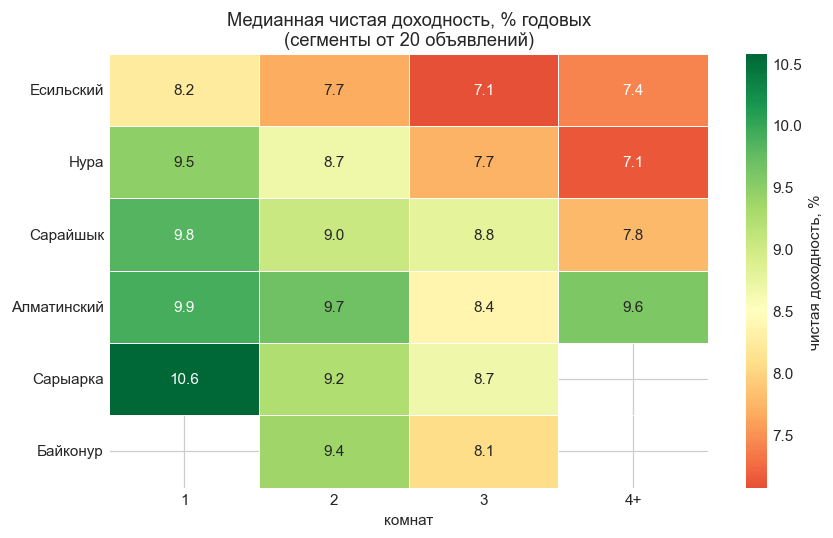

In [11]:
heat = (inv.groupby(["district", "rooms_grp"], observed=True)
          .agg(n=("net_yield", "size"), net_yield=("net_yield", "median"))
          .reset_index())
heat = heat[heat["n"] >= 20]
pivot = heat.pivot(index="district", columns="rooms_grp", values="net_yield").loc[DISTRICT_ORDER]
pivot.columns = ["1", "2", "3", "4+"]

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot * 100, annot=True, fmt=".1f", cmap="RdYlGn", center=8.5, linewidths=0.5,
            cbar_kws={"label": "чистая доходность, %"}, ax=ax)
ax.set(title="Медианная чистая доходность, % годовых\n(сегменты от 20 объявлений)", xlabel="комнат", ylabel="")
plt.tight_layout(); plt.show()

ranking = (inv.groupby(["district", "bank", "rooms_grp"], observed=True)
             .agg(квартир=("net_yield", "size"),
                  медиана_цены_млн=("price_mln", "median"),
                  аренда_в_мес=("est_rent", "median"),
                  чистая_доходность=("net_yield", "median"),
                  окупаемость_лет=("payback_years", "median"))
             .query("квартир >= 20")
             .sort_values("чистая_доходность", ascending=False))
ranking["место"] = range(1, len(ranking) + 1)
ranking.style.format({"медиана_цены_млн": "{:.1f}", "аренда_в_мес": "{:,.0f}",
                      "чистая_доходность": "{:.1%}", "окупаемость_лет": "{:.1f}"})

**Вывод.**
- **Лучшие сегменты — однушки на правом берегу:** Сарыарка (≈10,6% чистыми, окупаемость ≈9,5 лет),
  Алматинский район и Сарайшык (≈9,8–9,9%). Порог входа — 20–23 млн ₸.
- **Худшие — 2–4-комнатные квартиры в Есильском районе и большие квартиры в Нуре:** 7,1–7,7%,
  окупаемость 13–14 лет.
- Разница между лучшим и худшим сегментом — **≈3,5 п.п. годовых**, а срок окупаемости отличается
  на 4–5 лет. Именно эту разницу агентство может «продавать» клиенту как ценность подбора.

## 5.2. Как на самом деле росли цены и аренда в Астане

Чтобы не гадать о будущем росте цен, смотрим на историю: **годовые индексы цен на рынке жилья**
Бюро национальной статистики (декабрь к декабрю) по Астане — новое жильё, вторичка, аренда —
и сравниваем их с годовой инфляцией (ИПЦ, декабрь к декабрю).

> Файлы со stat.gov.kz → «Цены на рынке жилья» → «Индексы цен на рынке жилья» и «Цены на рынке жилья» (xlsx)
> сохранить как `data/stat/housing_indices.xlsx` и `data/stat/housing_prices.xlsx`.

In [12]:
def city_series(path, sheet, city="Астана"):
    """Достаёт строку города из динамической таблицы БНС: годы в заголовке, города в первой колонке."""
    t = pd.read_excel(path, sheet_name=sheet, header=None)
    header_row = t.index[t.iloc[:, 1].astype(str).str.match(r"^20\d\d")][0]
    years = t.iloc[header_row, 1:]
    row = t[t.iloc[:, 0].astype(str).str.strip().str.rstrip("*") == city].iloc[0, 1:]
    out = pd.Series(pd.to_numeric(row.values, errors="coerce"), index=pd.to_numeric(years.values, errors="coerce"))
    return out[out.index.notna()].astype(float).rename(lambda y: int(y))

IDX_FILE, PRICE_FILE = "data/stat/housing_indices.xlsx", "data/stat/housing_prices.xlsx"
hist = pd.DataFrame({
    "Вторичка": city_series(IDX_FILE, "Перепродажа квартир"),
    "Новостройки": city_series(IDX_FILE, "Продажа нового жилья"),
    "Аренда": city_series(IDX_FILE, "Аренда квартир"),
}) / 100

# Годовая инфляция (ИПЦ, декабрь к декабрю), Бюро национальной статистики РК
CPI = pd.Series({2016: 8.5, 2017: 7.1, 2018: 5.3, 2019: 5.4, 2020: 7.5,
                 2021: 8.4, 2022: 20.3, 2023: 9.8, 2024: 8.6, 2025: 12.3}) / 100 + 1
hist = hist.loc[CPI.index]
hist["Инфляция"] = CPI

def cagr(df, years):
    sub = df.tail(years)
    return sub.prod() ** (1 / years) - 1

growth = pd.DataFrame({f"за {n} лет ({2026 - n}–2025)": cagr(hist, n) for n in [3, 5, 10]}).T
real_growth = growth[["Вторичка", "Новостройки", "Аренда"]].apply(
    lambda col: (1 + col) / (1 + growth["Инфляция"]) - 1)

print("Среднегодовой рост, номинально:")
display(growth.style.format("{:+.1%}"))
print("Среднегодовой рост за вычетом инфляции (реально):")
display(real_growth.style.format("{:+.1%}"))

prices_2025 = pd.Series({"Вторичка": city_series(PRICE_FILE, "Перепродажа жилья")[2025],
                         "Новостройки": city_series(PRICE_FILE, "Продажа нового жилья")[2025],
                         "Аренда": city_series(PRICE_FILE, "Аренда жилья")[2025]})
print("Средние цены БНС по Астане, 2025, ₸ за м²:", prices_2025.round(0).to_dict())

Среднегодовой рост, номинально:


,Вторичка,Новостройки,Аренда,Инфляция
за 3 лет (2023–2025),+4.9%,+7.6%,+13.7%,+10.2%
за 5 лет (2021–2025),+13.4%,+12.8%,+18.4%,+11.8%
за 10 лет (2016–2025),+8.4%,+9.2%,+9.2%,+9.2%


Среднегодовой рост за вычетом инфляции (реально):


,Вторичка,Новостройки,Аренда
за 3 лет (2023–2025),-4.8%,-2.4%,+3.1%
за 5 лет (2021–2025),+1.5%,+0.9%,+5.9%
за 10 лет (2016–2025),-0.8%,-0.0%,-0.0%


Средние цены БНС по Астане, 2025, ₸ за м²: {'Вторичка': 720425.0, 'Новостройки': 671200.0, 'Аренда': 5551.0}


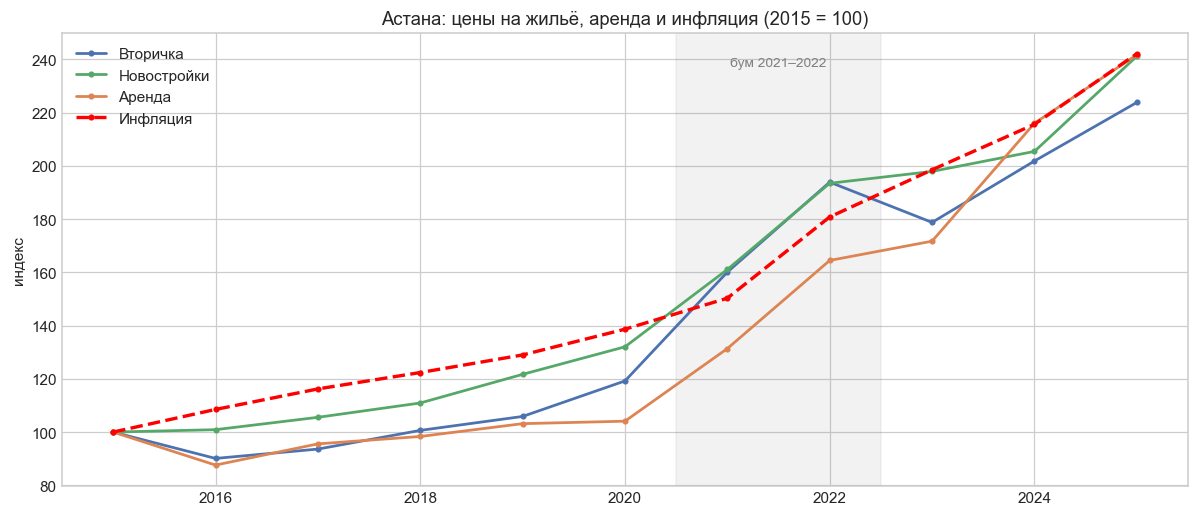

In [13]:
cum = hist.cumprod()
cum.loc[2015] = 1.0
cum = cum.sort_index() * 100

fig, ax = plt.subplots(figsize=(11, 4.8))
styles = {"Вторичка": ("#4C72B0", "-"), "Новостройки": ("#55A868", "-"),
          "Аренда": ("#DD8452", "-"), "Инфляция": ("red", "--")}
for col, (color, ls) in styles.items():
    ax.plot(cum.index, cum[col], color=color, ls=ls, lw=2.2 if col == "Инфляция" else 1.8, marker="o", ms=3, label=col)
ax.set(title="Астана: цены на жильё, аренда и инфляция (2015 = 100)", xlabel="", ylabel="индекс")
ax.legend()
ax.axvspan(2020.5, 2022.5, color="grey", alpha=0.1)
ax.text(2021.5, ax.get_ylim()[1] * 0.95, "бум 2021–2022", ha="center", fontsize=9, color="grey")
plt.tight_layout(); plt.show()

**Вывод.**
- **За 10 лет (2016–2025)** вторичка в Астане дорожала в среднем на **≈8,4% в год** при инфляции ≈9,2%:
  в реальном выражении цены **почти не выросли (≈ −0,8% в год)**. Аренда росла ровно вместе с инфляцией.
  Жильё в долгую **сохраняет**, но не приумножает деньги.
- **За 5 лет (2021–2025)** картина лучше: вторичка **+13,4% в год** против инфляции 11,8% (реально +1,5%),
  аренда — **+18,4% в год**. Но почти весь рост дали два года бума (2021–2022: +34% и +21%).
- **За 3 года (2023–2025)** вторичка росла лишь на ≈4,9% в год — **медленнее инфляции на ≈5 п.п.**
  (в 2023 году цены упали на 7,8%), зато аренда росла на ≈13,7% в год — быстрее инфляции.
- **Для инвестора:** рассчитывать на рост цен «как в 2021–2022» рискованно. Реалистичный базовый сценарий —
  цены растут примерно на уровне инфляции, а основную реальную доходность даёт **индексация аренды**.

**Свежие данные 2026 года** (публикации БНС): в июне 2026 вторичка в Астане подорожала за год на ≈13%,
новостройки — на ≈19%, но число сделок в Астане в августе 2026 упало на треть к прошлому году —
спрос охлаждается.

## 5.3. Аренда, депозит и инфляция: ROI за 5 лет

цены не растут             цены +0.0%/год, аренда +0.0%/год
рост 5%/год                цены +5.0%/год, аренда +5.0%/год
на уровне инфляции (11%)   цены +11.0%/год, аренда +11.0%/год
как в 2016–2025            цены +8.4%/год, аренда +9.2%/год
как в 2021–2025            цены +13.4%/год, аренда +18.4%/год


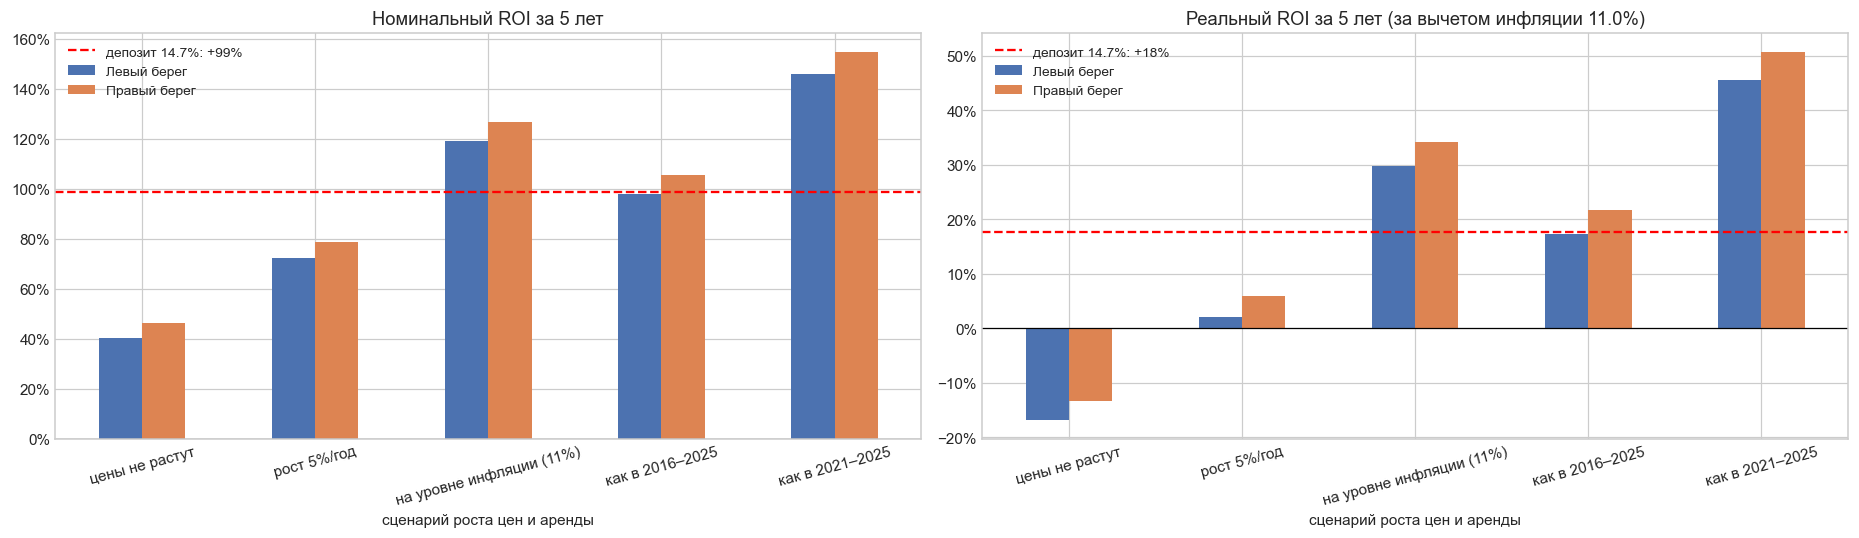

,"Аренда (чистая доходность, год)",Депозит (год)
номинально,+8.5%,+14.7%
реально (минус инфляция),-2.3%,+3.3%


In [14]:
# Сценарии: (рост цены квартиры, рост аренды) в год. Последние два — фактическая история Астаны.
g5, g10 = cagr(hist, 5), cagr(hist, 10)
SCENARIOS = {
    "цены не растут": (0.0, 0.0),
    "рост 5%/год": (0.05, 0.05),
    f"на уровне инфляции ({INFLATION:.0%})": (INFLATION, INFLATION),
    "как в 2016–2025": (g10["Вторичка"], g10["Аренда"]),
    "как в 2021–2025": (g5["Вторичка"], g5["Аренда"]),
}
for name, (g_price, g_rent) in SCENARIOS.items():
    income_5y = sum(inv["net_income"] * (1 + g_rent) ** t for t in range(5))
    roi = (income_5y + inv["price_kzt"] * ((1 + g_price) ** 5 - 1)) / inv["price_kzt"]
    inv[f"roi5 | {name}"] = roi
    inv[f"real_roi5 | {name}"] = (1 + roi) / (1 + INFLATION) ** 5 - 1
for name, (gp, gr) in SCENARIOS.items():
    print(f"{name:<26} цены {gp:+.1%}/год, аренда {gr:+.1%}/год")

nominal = inv.groupby("bank", observed=True)[[f"roi5 | {n}" for n in SCENARIOS]].median()
real = inv.groupby("bank", observed=True)[[f"real_roi5 | {n}" for n in SCENARIOS]].median()
nominal.columns = real.columns = list(SCENARIOS)

fig, axes = plt.subplots(1, 2, figsize=(17, 5), sharey=False)
for ax, data, dep, title in [
    (axes[0], nominal, deposit_5y, "Номинальный ROI за 5 лет"),
    (axes[1], real, deposit_5y_real, f"Реальный ROI за 5 лет (за вычетом инфляции {INFLATION:.1%})"),
]:
    data.T.plot.bar(ax=ax, rot=15, color=[BANK_COLORS[b] for b in data.index])
    ax.axhline(dep, color="red", ls="--", label=f"депозит {DEPOSIT_RATE:.1%}: {dep:+.0%}")
    ax.axhline(0, color="black", lw=0.8)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set(title=title, xlabel="сценарий роста цен и аренды", ylabel="")
    ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    "Аренда (чистая доходность, год)": [inv["net_yield"].median(), inv["real_net_yield"].median()],
    "Депозит (год)": [DEPOSIT_RATE, deposit_real],
}, index=["номинально", "реально (минус инфляция)"])
display(summary.style.format("{:+.1%}"))
display(pd.concat({"номинальный": nominal, "реальный": real}, axis=1).style.format("{:+.0%}"))

**Вывод — неудобный, но важный для агентства.**
- Медианная **чистая** доходность сдачи — **≈8,5% годовых**, а средняя инфляция за 2025–2026 — **≈11%**.
  В реальном выражении одна только аренда даёт **около −2,3% в год**: деньги клиента обесцениваются.
  Инфляцию обгоняют лишь **≈14%** квартир. Депозит под 14,7% даёт **≈+3,3% в год реально**.
- Покупка под сдачу выигрывает только **вместе с ростом цен**. Что получается при разных сценариях
  (медиана по городу, ROI за 5 лет номинально / реально):
  - цены не растут — ≈43% / **−15%**, хуже депозита;
  - цены и аренда растут на уровне инфляции (11%) — ≈122% / **+32%**, лучше депозита (≈99% / +18%);
  - **как в 2016–2025** (цены +8,4%, аренда +9,2% в год) — ≈101% / **+19%** — практически **ничья с депозитом**;
  - как в 2021–2025 (бум: цены +13,4%, аренда +18,4% в год) — ≈149% / +48%, но повторения бума ждать рискованно.
- **Главный вывод по истории:** на длинном горизонте (10 лет) квартира в Астане приносит примерно столько же,
  сколько депозит, — с бóльшим риском и меньшей ликвидностью. Выигрыш появляется в периоды роста цен
  и в правильных сегментах (правый берег, однушки), где доходность выше средней.
- **Правый берег выигрывает у левого в любом сценарии** — на 4–9 п.п. ROI за 5 лет.
- **Рекомендация для коммуникации с клиентом:** продавать не «доход от аренды», а «сохранение капитала в
  реальном активе + арендный доход», честно показывая сравнение с депозитом и сценарий «цены не растут».

## 5.4. Шорт-лист для брокеров: самые доходные квартиры в бюджете клиентов

In [15]:
import glob
raw = pd.read_csv(sorted(glob.glob("data/raw/listings_*.csv"))[-1])
raw_urls = raw[["id", "url", "address"]].rename(columns={"id": "listing_id"})
shortlist = (inv[inv["in_client_budget"]]
             .nlargest(20, "net_yield")
             .merge(raw_urls, on="listing_id", how="left")
             [["district", "rooms", "area_m2", "floor", "floors_total", "price_mln", "est_rent",
               "net_yield", "payback_years", "address", "url"]])
shortlist.to_csv("data/shortlist_top20.csv", index=False, encoding="utf-8-sig")
inv.to_pickle("data/investment_metrics.pkl")
print(f"Медианная чистая доходность в бюджете 20–50 млн: {inv.loc[inv['in_client_budget'], 'net_yield'].median():.1%}")
shortlist.head(10).style.format({"price_mln": "{:.1f}", "est_rent": "{:,.0f}", "net_yield": "{:.1%}",
                                 "payback_years": "{:.1f}", "area_m2": "{:.0f}"})

Медианная чистая доходность в бюджете 20–50 млн: 9.1%


,district,rooms,area_m2,floor,floors_total,price_mln,est_rent,net_yield,payback_years,address,url
0,Алматинский,4,130,4,6,42.5,"771,940",17.8%,5.6,"Алматы р-н, Абылай хана 1",https://krisha.kz/a/show/1015934075
1,Алматинский,2,76,1,6,23.0,"384,218",16.3%,6.1,"Алматы р-н, Армандастар 2/3",https://krisha.kz/a/show/1012530169
2,Сарайшык,2,63,,,22.8,"354,391",15.2%,6.6,"Сарайшык р-н, А102",https://krisha.kz/a/show/679559059
3,Сарайшык,2,64,,,23.2,"359,476",15.2%,6.6,"Сарайшык р-н, А102",https://krisha.kz/a/show/679559058
4,Сарайшык,2,58,,,21.0,"325,277",15.2%,6.6,"Сарайшык р-н, А102",https://krisha.kz/a/show/679559063
5,Алматинский,4,90,6,9,34.5,"534,420",15.1%,6.6,"Алматы р-н, жумабаева 1",https://krisha.kz/a/show/1017088012
6,Алматинский,4,77,2,6,29.6,"457,820",15.1%,6.6,"Алматы р-н, Мусрепова 7/3",https://krisha.kz/a/show/1016433770
7,Нура,3,114,4,11,39.5,"602,604",14.9%,6.7,"Нура р-н, Туран 89/3",https://krisha.kz/a/show/1015259289
8,Сарайшык,3,75,,,27.0,"403,444",14.6%,6.8,"Сарайшык р-н, А102",https://krisha.kz/a/show/679559056
9,Сарайшык,3,81,,,29.2,"436,239",14.6%,6.8,"Сарайшык р-н, А102",https://krisha.kz/a/show/679559057


**Вывод.** В шорт-листе — квартиры с оценочной чистой доходностью 14–18%, то есть на уровне депозита
и выше. Почти все они на правом берегу (Алматинский район, Сарайшык). **Важно:** высокая оценочная доходность
часто означает, что квартира дешёвая для своего сегмента. Перед рекомендацией клиенту брокер обязан проверить
причину (состояние, ремонт, дом, документы). Полная модель «справедливой цены» — на этапе 6.

Файлы: `data/shortlist_top20.csv` (для брокеров), `data/investment_metrics.pkl` (для следующих этапов).

## Итоги метрик

1. **Медиана по Астане:** валовая доходность ≈10,5%, чистая ≈8,5%, окупаемость ≈11,7 лет.
2. **Правый берег доходнее левого:** 9,3% против 8,0% чистыми, окупаемость 10,8 против 12,4 лет.
3. **Однушки доходнее:** 9,3% против 7,8% у трёшек.
4. **С учётом средней инфляции 2025–2026 (≈11%) одна аренда даёт около −2,3% в год реально** — меньше депозита
   (+3,3% реально).
5. **История цен (БНС, 2016–2025):** вторичка в Астане росла на ≈8,4% в год при инфляции ≈9,2% — в реальном выражении
   цены стояли на месте. Если следующие 5 лет повторят последние 10, ROI квартиры (≈101%) ≈ депозиту (≈99%).
   Квартира выигрывает, только если цены растут не медленнее инфляции — как в 2021–2022, но не как в 2023–2025.